# TP4 — Detección de eventos atípicos en GDELT 2.0

**Materia:** Ingeniería de Datos · **Datos:** eventos GDELT 2.0 publicados entre el **13/10/2026 y el 19/10/2026**
(7 días completos, 672 archivos `export.CSV` de 15 minutos).

**Objetivo:** encontrar eventos "raros" que valga la pena investigar. Para eso se arma una tabla desnormalizada
(*One Big Table*), se limpia, se construye la matriz de datos, se reduce su dimensionalidad con ACP y sobre el
modelo resultante se marcan los atípicos multivariantes con T² de Hotelling y SPE (Q).

---

## Declaración de uso de Inteligencia Artificial

| Herramienta | Propósito |
|---|---|
| **Claude Opus 5.5** (Claude Code) | Organización del proyecto en carpetas (`data/raw`, `data/processed`, `src`, `notebooks`), código fuente de la ingesta, de la OBT, de la limpieza, de la matriz de datos, del ACP y de la detección de atípicos, armado de este notebook y redacción de las interpretaciones a partir de los resultados. |

Las decisiones metodológicas (ventana, criterios de nulos/ceros, variables descartadas, cantidad de componentes,
nivel α) fueron discutidas y revisadas por el equipo. La **guía de instrucciones** para reproducir el trabajo con la
IA está al final del notebook (sección 4) y en [`GUIA_IA.md`](../GUIA_IA.md).

---

## Organización del proyecto

```
TP4/
├── config.toml            # parámetros: ventana, umbrales de nulos y 'OTHER', variables, ACP, α
├── requirements.txt
├── GUIA_IA.md             # guía de instrucciones (human-in-the-loop)
├── data/
│   ├── raw/               # manifiesto + export.CSV.zip tal como los publica GDELT + tablas de códigos
│   └── processed/         # OBT, eventos limpios, matriz, scores del ACP y tabla de atípicos (parquet)
├── src/
│   ├── config.py          # lectura de config.toml
│   ├── ingesta.py         # manifiesto (masterfilelist), descarga con MD5, parseo de las 61 columnas
│   ├── obt.py             # One Big Table: evento + descripciones de todos los códigos
│   ├── limpieza.py        # perfil de nulos/ceros, descarte, imputación, NZV
│   ├── matriz.py          # reducción de cardinalidad ('OTHER' < 5 %), dummies, matriz X
│   ├── acp.py             # ACP, análisis paralelo de Horn, scree plot, cargas
│   ├── atipicos.py        # T² de Hotelling, SPE (Q), contribuciones, tabla de atípicos
│   └── pipeline.py        # raw -> OBT
└── notebooks/
    ├── TP4.ipynb          # este notebook
    └── consigna_tp4.ipynb
```

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import acp, atipicos, limpieza
from src.config import cargar_config
from src.matriz import construir_matriz, codificar_dummies, reducir_cardinalidad, tabla_cardinalidad
from src.obt import diccionario_obt
from src.pipeline import ejecutar

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", context="notebook")

cfg = cargar_config(RAIZ / "config.toml")
print(f"Ventana: {cfg.fecha_inicio} a {cfg.fecha_fin} ({cfg.ingesta['dias']} días) | umbral OTHER: {cfg.matriz['umbral_otros']:.0%}")

Ventana: 2026-10-13 a 2026-10-19 (7 días) | umbral OTHER: 5%


# 1) Ingesta de datos

## 1.1 Manifiesto, descarga y verificación de integridad

- **Fuente de verdad del listado:** `masterfilelist.txt` trae, por cada archivo de 15 minutos, su tamaño, su MD5 y su URL.
  El archivo pesa ~130 MB y está ordenado cronológicamente, así que `src/ingesta.py::construir_manifiesto` pide solo la
  **cola** con un `HTTP Range` y la agranda hasta cubrir el inicio de la ventana. El manifiesto filtrado se guarda en
  `data/raw/manifiesto_export.csv`.
- **Descarga:** concurrente, con reintentos y *backoff* exponencial; cada ZIP se valida contra su **MD5** del manifiesto
  y se guarda crudo en `data/raw/gdelt/20261013_20261019/` (si ya está y el MD5 coincide, se reutiliza).
- **Parseo:** las 61 columnas del codebook con `pyarrow`, con tipos explícitos (los códigos CAMEO quedan como texto
  para no perder ceros a la izquierda) y sin comillas como delimitador de campo (GDELT no las usa). Si un
  `GlobalEventID` aparece más de una vez, se conserva la versión con `DATEADDED` más reciente.

La celda siguiente corre la pipeline `raw → OBT` completa.

In [2]:
salida = ejecutar(cfg)
manifiesto, reporte, obt = salida["manifiesto"], salida["reporte_descarga"], salida["obt"]

[1/3] Manifiesto de la ventana 2026-10-13 a 2026-10-19 (masterfilelist.txt)


      672 archivos export.CSV.zip (46.2 MB)
[2/3] Descargando a data/raw (con verificación MD5)


      descargado: 672
[3/3] Parseando y construyendo la One Big Table


      OBT: 729,663 eventos x 81 columnas -> data/processed/obt_eventos.parquet
Listo en 12.8 s


Archivos esperados: 672 | en el manifiesto: 672 | faltantes: 0
Estado de la descarga: {'descargado': 672}


,count,mean,std,min,25%,50%,75%,max
eventos por archivo,672.0,1085.8,388.1,287.0,789.8,1078.0,1340.5,2540.0


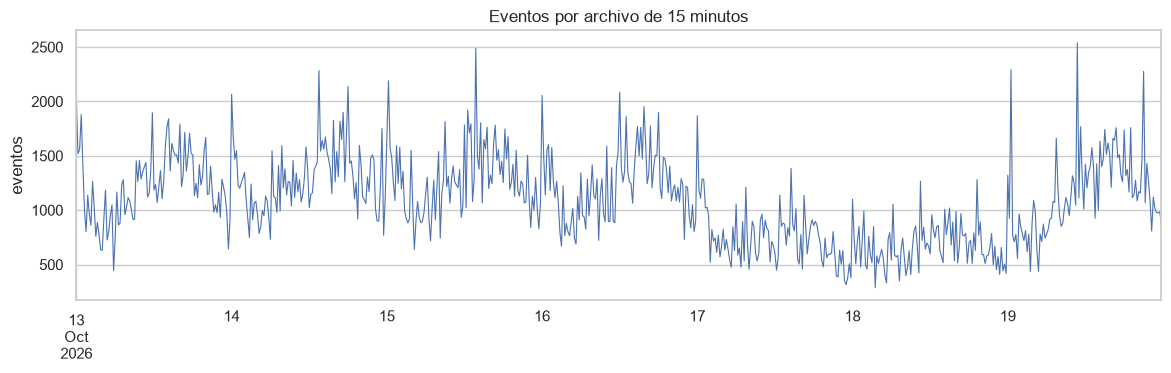

In [3]:
# Completitud de la ventana: 7 días x 96 archivos esperados
esperados = pd.date_range(*cfg.ventana, freq="15min", inclusive="left")
faltantes = esperados.difference(pd.DatetimeIndex(manifiesto["timestamp"]))
print(f"Archivos esperados: {len(esperados)} | en el manifiesto: {len(manifiesto)} | faltantes: {len(faltantes)}")
print("Estado de la descarga:", reporte["estado"].value_counts().to_dict())

por_archivo = obt.groupby("DateAdded").size()
fig, ax = plt.subplots(figsize=(14, 3.5))
por_archivo.plot(ax=ax, lw=0.8)
ax.set_title("Eventos por archivo de 15 minutos"); ax.set_ylabel("eventos"); ax.set_xlabel("")
por_archivo.describe().round(1).to_frame("eventos por archivo").T

## 1.2 One Big Table

En los TP anteriores el modelo era un esquema estrella. Acá se pide lo opuesto: una **tabla desnormalizada**
donde cada fila es un evento con *todo* lo necesario para analizarlo sin JOINs (`src/obt.py`):

- las **61 columnas originales** del `export.CSV` (con los nulos tal como vienen, para tratarlos en la limpieza);
- las **descripciones de los códigos**: acción CAMEO (código, base y raíz), `QuadClass` y sus ejes,
  tipo y país de cada actor (`CAMEO.type`, `CAMEO.country`), país FIPS de las tres geografías y tipo de geocodificación;
- **atributos derivados**: fecha del evento y de publicación, `LagDays` (días entre el evento y su publicación),
  hora y día de la semana de publicación y dominio del medio (`SourceDomain`).

Se guarda en `data/processed/obt_eventos.parquet` (formato columnar, comprimido y con tipos).

In [4]:
print(f"OBT: {obt.shape[0]:,} eventos x {obt.shape[1]} columnas | "
      f"{cfg.ruta('obt').stat().st_size / 1e6:.1f} MB en parquet | GlobalEventID único: {obt['GlobalEventID'].is_unique}")
diccionario_obt(obt).query("origen == 'derivada'")

OBT: 729,663 eventos x 81 columnas | 61.4 MB en parquet | GlobalEventID único: True


,origen,tipo,ejemplo
EventDate,derivada,datetime64[us],2025-10-13 00:00:00
DateAdded,derivada,datetime64[us],2026-10-13 00:00:00
LagDays,derivada,Int64,365
HourAdded,derivada,Int8,0
WeekdayAdded,derivada,str,Tuesday
EventDesc,derivada,str,"Express intent to cooperate, not specified below"
EventBaseDesc,derivada,str,"Express intent to cooperate, not specified below"
EventRootDesc,derivada,str,03 EXPRESS INTENT TO COOPERATE
QuadClassDesc,derivada,str,Cooperación verbal
CoopConflictAxis,derivada,str,Cooperación


In [5]:
obt.sample(3, random_state=cfg.acp["semilla"]).T.head(90)

,138576,657100,453260
GlobalEventID,1327829594,1328676206,1328338611
Day,20261014,20261019,20261016
MonthYear,202610,202610,202610
Year,2026,2026,2026
FractionDate,2026.7781,2026.7918,2026.7836
...,...,...,...
Actor1Geo_CountryName,NaN,Philippines,United States
Actor2Geo_CountryName,NaN,Philippines,United States
ActionGeo_CountryName,NaN,Philippines,United States
ActionGeo_TypeDesc,NaN,WORLDCITY,USCITY


# 2) Limpieza

## 2.1 Nulos y ceros

Primero se perfila cada columna del `export.CSV`: proporción de nulos y, en las numéricas, de ceros.

In [6]:
perfil = limpieza.perfil_faltantes(obt)
perfil_export = perfil.loc[[c for c in perfil.index if c in obt.columns[:61]]]
con_faltantes = perfil_export[(perfil_export["pct_nulos"] > 0) | (perfil_export["pct_ceros"] > 0)]
con_faltantes.sort_values("pct_nulos", ascending=False)

,tipo,nulos,pct_nulos,ceros,pct_ceros
columna,,,,,
Actor2Type3Code,str,729362,99.959,NaN,NaN
Actor1Type3Code,str,729222,99.940,NaN,NaN
Actor2Religion2Code,str,727418,99.692,NaN,NaN
Actor1Religion2Code,str,727000,99.635,NaN,NaN
Actor2EthnicCode,str,726372,99.549,NaN,NaN
Actor1EthnicCode,str,725580,99.440,NaN,NaN
Actor2KnownGroupCode,str,723104,99.101,NaN,NaN
Actor1KnownGroupCode,str,721663,98.904,NaN,NaN
Actor2Religion1Code,str,721486,98.879,NaN,NaN


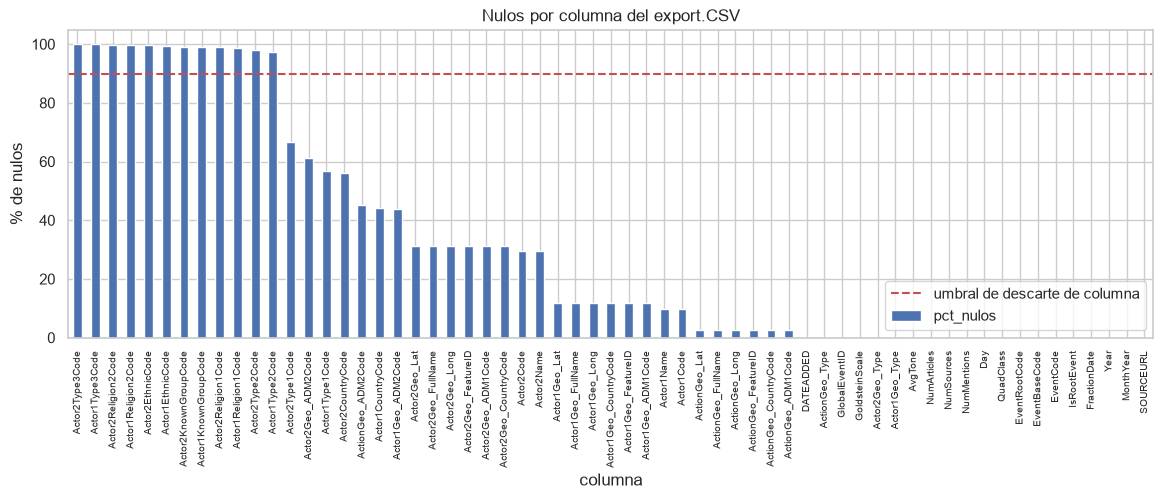

In [7]:
fig, ax = plt.subplots(figsize=(14, 4))
perfil_export["pct_nulos"].sort_values(ascending=False).plot.bar(ax=ax, color="#4C72B0")
ax.axhline(100 * cfg.limpieza["umbral_nulos_columna"], ls="--", color="#C44E52", label="umbral de descarte de columna")
ax.set_ylabel("% de nulos"); ax.set_title("Nulos por columna del export.CSV"); ax.tick_params(axis="x", labelsize=7); ax.legend();

### ¿Qué significa cada faltante?

Siguiendo lo visto en clase, no todo nulo es un error ni todo cero es un faltante. Antes de decidir, se revisa
qué representa cada caso según el codebook:

In [8]:
chequeos = pd.Series({
    "Actor1Code nulo (sin actor 1)": obt["Actor1Code"].isna().mean(),
    "Actor2Code nulo (sin actor 2)": obt["Actor2Code"].isna().mean(),
    "Actor1: hay actor pero Type1Code nulo": (obt["Actor1Code"].notna() & obt["Actor1Type1Code"].isna()).mean(),
    "Actor1: hay actor pero CountryCode nulo": (obt["Actor1Code"].notna() & obt["Actor1CountryCode"].isna()).mean(),
    "ActionGeo_Type = 0 (sin geocodificación)": obt["ActionGeo_Type"].eq(0).mean(),
    "  ... y ActionGeo_CountryCode nulo en esos casos": obt.loc[obt["ActionGeo_Type"].eq(0), "ActionGeo_CountryCode"].isna().mean(),
    "ActionGeo_Lat = 0 con ubicación válida": (obt["ActionGeo_Lat"].eq(0) & obt["ActionGeo_Type"].gt(0)).mean(),
    "GoldsteinScale nulo": obt["GoldsteinScale"].isna().mean(),
    "GoldsteinScale = 0": obt["GoldsteinScale"].eq(0).mean(),
    "AvgTone = 0": obt["AvgTone"].eq(0).mean(),
    "IsRootEvent = 0": obt["IsRootEvent"].eq(0).mean(),
    "NumMentions / NumSources / NumArticles = 0": obt[["NumMentions", "NumSources", "NumArticles"]].eq(0).any(axis=1).mean(),
}, name="% de eventos").mul(100).round(3)
chequeos.to_frame()

,% de eventos
Actor1Code nulo (sin actor 1),9.582
Actor2Code nulo (sin actor 2),29.461
Actor1: hay actor pero Type1Code nulo,47.266
Actor1: hay actor pero CountryCode nulo,34.468
ActionGeo_Type = 0 (sin geocodificación),2.596
... y ActionGeo_CountryCode nulo en esos casos,99.398
ActionGeo_Lat = 0 con ubicación válida,0.023
GoldsteinScale nulo,0.000
GoldsteinScale = 0,10.899
AvgTone = 0,1.896


In [9]:
# Goldstein nulo: ¿qué códigos CAMEO son?
display(obt.loc[obt["GoldsteinScale"].isna(), ["GlobalEventID", "EventCode", "EventBaseCode", "EventRootCode", "EventDesc", "EventBaseDesc", "QuadClassDesc"]])

# Ceros en Goldstein: ¿a qué acciones corresponden?
display(obt.loc[obt["GoldsteinScale"].eq(0), "EventDesc"].value_counts().head(5).to_frame("eventos con Goldstein = 0"))

# Latitud 0 con ubicación: ¿dónde?
display(obt.loc[obt["ActionGeo_Lat"].eq(0) & obt["ActionGeo_Type"].gt(0), "ActionGeo_FullName"].value_counts().head(5).to_frame("ActionGeo_Lat = 0"))

# Desfase entre el evento y su publicación
obt["LagDays"].value_counts().sort_index().to_frame("eventos").T

,GlobalEventID,EventCode,EventBaseCode,EventRootCode,EventDesc,EventBaseDesc,QuadClassDesc
211644,1327952321,1213,121,12,NaN,Reject material cooperation,Conflicto verbal
211645,1327952322,1213,121,12,NaN,Reject material cooperation,Conflicto verbal
278728,1328052789,1213,121,12,NaN,Reject material cooperation,Conflicto verbal


,eventos con Goldstein = 0
EventDesc,
"Make statement, not specified below",63644
Consider policy option,8014
Engage in symbolic act,4385
Acknowledge or claim responsibility,3485


,ActionGeo_Lat = 0
ActionGeo_FullName,
Democratic Republic Of The Congo,71
"Sumatra, Indonesia (general), Indonesia",37
"West Kalimantan, Kalimantan Barat, Indonesia",32
"Congo Basin, , Congo",19
"Ramogi, Nyanza, Kenya",5


LagDays,0,1,7,30,365,3650
eventos,715129,1496,4458,4274,4140,166


### Criterio de tratamiento

| Caso | % de eventos | Tipo de faltante | Decisión |
|---|---|---|---|
| `Actor*KnownGroupCode`, `EthnicCode`, `Religion1/2Code`, `Type2/3Code` (12 columnas) | 97–99,9 % nulos | atributos opcionales que GDELT casi nunca completa | **Descartar la columna** del análisis (umbral 90 %; siguen en la OBT) |
| `Actor1Code` / `Actor2Code` nulos | 9,6 % / 29,5 % | **nulo estructural**: el evento tiene un solo actor o GDELT no lo identificó | Recodificar como `SIN_ACTOR` |
| `Actor*Type1Code` nulo con actor presente | 47,3 % (actor 1) | **nulo estructural**: el actor está codificado solo por país o es genérico (`USA`, `GBR`) | Recodificar como `SIN_TIPO` |
| `ActionGeo_Type = 0` | 2,6 % | **cero estructural**: es el código de "sin ubicación" (en el 99,4 % de esos casos el país también es nulo) | Recodificar país y tipo de geo como `SIN_UBICACION` |
| `GoldsteinScale` nulo | 3 eventos | **nulo real**: el código CAMEO `1213` no figura en las tablas del codebook | **Imputar** con la regla del codebook: el puntaje Goldstein es función del código CAMEO, así que se toma el de su código base `121` (−4,0) de `CAMEO.goldsteinscale.txt` |
| `GoldsteinScale = 0` | 10,9 % | **cero válido**: acciones neutras de la escala (*Make statement*, *Consider policy option*…) | Conservar |
| `AvgTone = 0` | 1,9 % | **cero válido**: tono neutro | Conservar |
| `ActionGeo_Lat = 0` con ubicación | 0,02 % | **cero válido**: lugares sobre el ecuador (Congo, Sumatra, Kalimantan) | Conservar (no entra a la matriz) |
| `IsRootEvent = 0` | 47,6 % | variable binaria | Conservar |
| `NumMentions/NumSources/NumArticles = 0` | 0 % | — | — |

**Por qué casi no se descartan filas.** Todos los nulos de las variables del análisis son estructurales o
imputables por regla. Descartar filas con algún nulo eliminaría el 9,6 % de los eventos (sin actor 1) o el 29,5 %
(sin actor 2), y el resultado quedaría sesgado hacia eventos con dos actores bien identificados. Para encontrar
eventos raros eso es justo lo contrario de lo que se busca. La regla de descarte de filas (fecha inválida o variable
obligatoria nula después de imputar) queda implementada, pero en esta ventana no se activó.

**`LagDays` toma solo 6 valores** (0, 1, 7, 30, 365 y 3650 días). GDELT fecha el evento a partir de expresiones
relativas del texto ("ayer", "la semana pasada", "hace un año", "hace una década"). No es un error de carga, pero
el 2 % de eventos con desfase son candidatos naturales a atípicos y se conservan.

In [10]:
eventos, registro = limpieza.limpiar(obt, cfg)
for k, v in registro.items():
    print(f"{k:<24} {v}")

filas_iniciales          729663
columnas_descartadas     ['Actor1KnownGroupCode', 'Actor1EthnicCode', 'Actor1Religion1Code', 'Actor1Religion2Code', 'Actor1Type2Code', 'Actor1Type3Code', 'Actor2KnownGroupCode', 'Actor2EthnicCode', 'Actor2Religion1Code', 'Actor2Religion2Code', 'Actor2Type2Code', 'Actor2Type3Code']
goldstein_imputados      3
filas_fecha_invalida     0
filas_sin_obligatorias   0
filas_finales            729663


In [11]:
# Verificación: los 3 Goldstein imputados y ningún nulo en las variables que entran a la matriz
display(eventos.loc[eventos["GoldsteinImputed"].eq(1), ["GlobalEventID", "EventCode", "EventBaseCode", "GoldsteinScale"]])
vars_matriz = cfg.matriz["continuas"] + cfg.matriz["binarias"] + cfg.matriz["categoricas"]
print("Nulos en las variables de la matriz:", int(eventos[vars_matriz].isna().sum().sum()))
eventos[["Actor1Type", "Actor2Type", "ActionGeo_TypeDesc"]].apply(lambda s: s.value_counts(normalize=True).mul(100).round(1).head(6)).fillna("")

,GlobalEventID,EventCode,EventBaseCode,GoldsteinScale
211644,1327952321,1213,121,-4.0
211645,1327952322,1213,121,-4.0
278728,1328052789,1213,121,-4.0


Nulos en las variables de la matriz: 0


,Actor1Type,Actor2Type,ActionGeo_TypeDesc
Business,3.4,2.8,
COUNTRY,,,21.0
Civilian,3.4,3.3,
Education,,2.7,
Government,13.2,9.4,
Police forces,3.7,,
SIN_ACTOR,9.6,29.5,
SIN_TIPO,47.3,37.3,
SIN_UBICACION,,,2.6
USCITY,,,16.1


### Atributos sin información (*near zero variance*)

Se calcula el coeficiente de variación $CV = \sigma/\mu$ y la razón entre la frecuencia de la moda y la del segundo
valor más frecuente para las numéricas candidatas.

In [12]:
nzv = limpieza.near_zero_variance(eventos, ["GoldsteinScale", "AvgTone", "NumMentions", "NumSources", "NumArticles", "LagDays", "IsRootEvent"], cfg.limpieza["cv_minimo"])
nzv

,media,desvio,cv,pct_moda,razon_frecuencias,valores_unicos,nzv_por_cv
variable,,,,,,,
GoldsteinScale,0.482,4.592,9.517,10.899,1.131,42,False
AvgTone,-1.969,4.166,2.116,1.896,22.319,63988,False
NumMentions,4.690,4.486,0.957,26.346,1.780,116,False
NumSources,1.051,0.461,0.438,97.329,53.321,19,False
NumArticles,4.580,4.180,0.913,26.581,1.789,107,False
LagDays,3.122,61.503,19.701,98.008,160.415,6,False
IsRootEvent,0.524,0.499,0.954,52.357,1.099,2,False


In [13]:
# Redundancia entre conteos: misma información medida dos veces
eventos[["NumMentions", "NumSources", "NumArticles"]].apply(np.log1p).corr().round(3)

,NumMentions,NumSources,NumArticles
NumMentions,1.000,0.226,0.992
NumSources,0.226,1.000,0.228
NumArticles,0.992,0.228,1.000


**Interpretación.** Ninguna variable cae por debajo de CV = 0,05, así que por ese criterio no hay variables sin
información. Pero `NumSources` (97,3 % de los eventos con 1 fuente) y `LagDays` (98 % con desfase 0) tienen una
razón entre la moda y el segundo valor de 53 y 160: con el criterio de frecuencias serían *near zero variance*.
**Se conservan a propósito.** En este TP lo raro *es* la señal: un evento recogido por 20 fuentes, o fechado diez
años antes de su publicación, es exactamente lo que se quiere detectar. Si se eliminaran, desaparecerían dos de las
principales fuentes de atipicidad.

En cambio, **`NumArticles` se descarta de la matriz** por redundancia. Su correlación con `NumMentions` en escala
log es 0,992 (cada artículo que menciona el evento suma una mención). Si se dejaran las dos, esa información
entraría dos veces al ACP y aparecería una componente casi nula (autovalor ≈ 0,008 en una prueba previa).

In [14]:
eventos.to_parquet(cfg.ruta("eventos_limpios"), index=False)
print(f"Eventos limpios: {len(eventos):,} -> {cfg.rutas['eventos_limpios']}")

Eventos limpios: 729,663 -> data/processed/eventos_limpios.parquet


## 2.2 Reducción de cardinalidad

Las categorías con frecuencia relativa **< 5 %** se agrupan como `'OTHER'` antes de codificar
(`src/matriz.py::reducir_cardinalidad`). Variables categóricas de la matriz:

| Variable | Qué describe |
|---|---|
| `EventRootDesc` | código raíz CAMEO de la acción (20 categorías) |
| `Actor1Type`, `Actor2Type` | tipo de cada actor (`Type1Code`) con `SIN_ACTOR` / `SIN_TIPO` |
| `ActionGeo_TypeDesc` | precisión de la geocodificación de la acción (país, estado, ciudad…) |
| `ActionGeo_CountryName` | país donde ocurre la acción (FIPS 10-4) |

`QuadClass` **no entra**: el codebook la define a partir del código raíz (01–05 cooperación verbal, 06–08 cooperación
material, 09–13 conflicto verbal, 14–20 conflicto material), así que no agrega información (ver 2.3).

In [15]:
cats_cfg = cfg.matriz["categoricas"]
cats_orig = eventos[cats_cfg]
cats_red = cats_orig.apply(reducir_cardinalidad, umbral=cfg.matriz["umbral_otros"], etiqueta=cfg.matriz["etiqueta_otros"])
tabla_cardinalidad(cats_orig, cats_red, cats_cfg)

,categorias_originales,categorias_finales,categorias_agrupadas,pct_filas_en_OTHER
variable,,,,
EventRootDesc,20,8,13,25.57
Actor1Type,34,4,31,29.95
Actor2Type,34,4,31,23.82
ActionGeo_TypeDesc,6,5,2,5.47
ActionGeo_CountryName,245,4,242,58.35


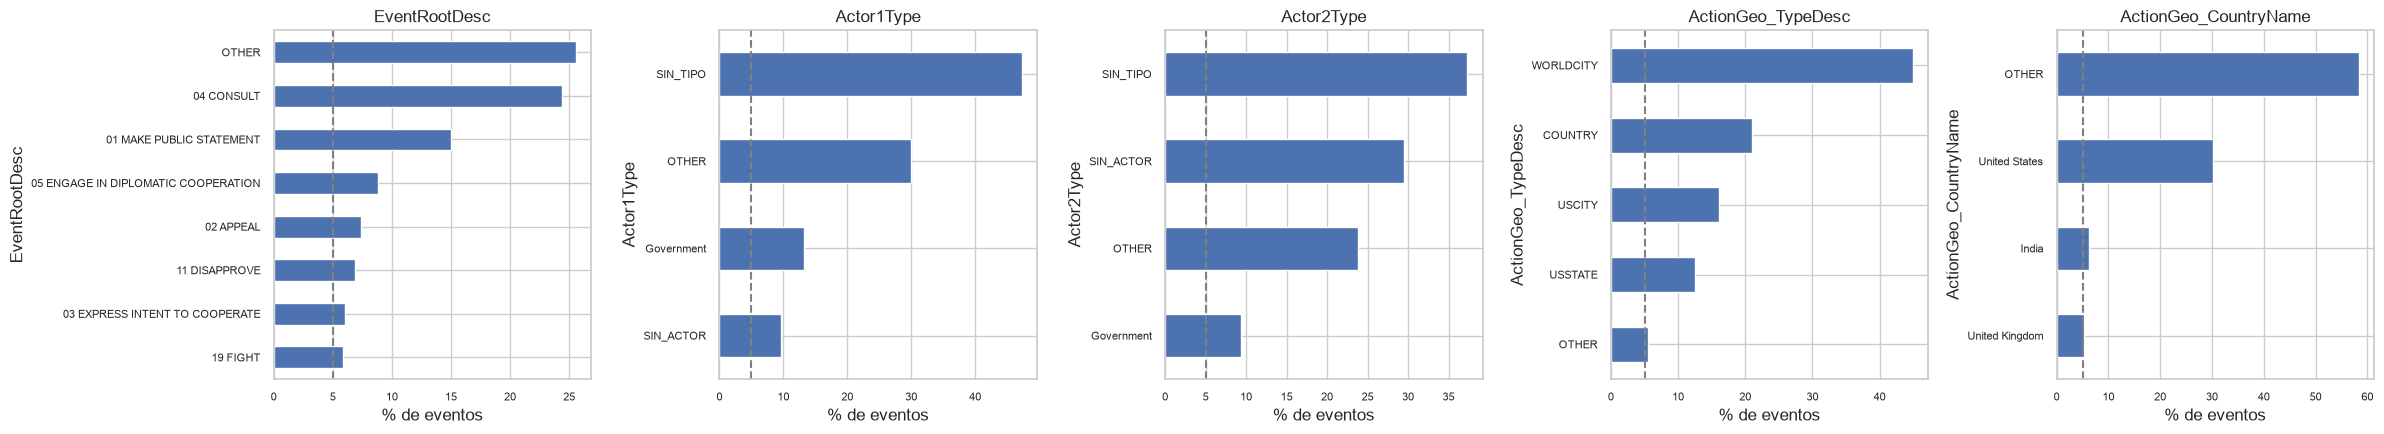

In [16]:
fig, axes = plt.subplots(1, len(cats_cfg), figsize=(24, 4.5))
for ax, c in zip(axes, cats_cfg):
    (100 * cats_red[c].value_counts(normalize=True)).sort_values().plot.barh(ax=ax, color="#4C72B0")
    ax.axvline(100 * cfg.matriz["umbral_otros"], ls="--", color="gray")
    ax.set_title(c); ax.set_xlabel("% de eventos"); ax.tick_params(labelsize=8)
plt.tight_layout()

**Interpretación.**

- **`OTHER` no es marginal.** Agrupa el 25,6 % de los eventos en `EventRootDesc`, donde es la categoría más grande
  (por encima de *04 CONSULT*, 24,4 %). En `ActionGeo_CountryName` llega al 58,4 %: solo EE. UU. (30,2 %), India
  (6,2 %) y Reino Unido (5,3 %) superan el 5 % entre 245 países.
- **Tipos de actor:** de 34 tipos solo *Government* supera el umbral. El resto de la variable lo explican los dos
  nulos estructurales (`SIN_TIPO` 47 % / 37 %, `SIN_ACTOR` 10 % / 30 %), que sí quedan como categorías propias.
- **`ActionGeo_TypeDesc`:** solo `WORLDSTATE` (2,9 %) y `SIN_UBICACION` (2,6 %) pasan a `OTHER` (5,5 %).
- **Costo para la detección de atípicos:** un país o un tipo de actor raro *por sí solo* deja de ser visible, porque
  queda dentro de `OTHER`. Lo que el modelo puede detectar son combinaciones raras entre categorías frecuentes y
  valores extremos de las continuas. Es el precio de pasar de ~340 categorías a 25 y evitar indicadoras con
  p ≈ 0,001, que al estandarizarse valdrían ≈ 30 desvíos y convertirían cualquier categoría rara en un "atípico"
  trivial.

## 2.3 Variables indicadoras (dummy)

Cada categórica reducida se transforma en indicadoras 0/1 (`src/matriz.py::codificar_dummies`). Por cada variable
se descarta la indicadora de la **categoría de referencia** (`OTHER`) para evitar la trampa de las variables dummy
(las indicadoras de una variable suman 1 en cada fila → colinealidad perfecta con la constante).

In [17]:
X, cats, referencias = construir_matriz(eventos, cfg)
print("Categoría de referencia descartada por variable:")
for var, ref in referencias.items():
    print(f"  {var:<22} -> {ref}")
print(f"\nMatriz X: {X.shape[0]:,} eventos x {X.shape[1]} variables "
      f"({len(cfg.matriz['continuas'])} continuas, {len(cfg.matriz['binarias'])} binaria, {X.shape[1] - len(cfg.matriz['continuas']) - len(cfg.matriz['binarias'])} indicadoras)")
X.head()

Categoría de referencia descartada por variable:
  EventRootDesc          -> OTHER
  Actor1Type             -> OTHER
  Actor2Type             -> OTHER
  ActionGeo_TypeDesc     -> OTHER
  ActionGeo_CountryName  -> OTHER

Matriz X: 729,663 eventos x 26 variables (5 continuas, 1 binaria, 20 indicadoras)


,GoldsteinScale,AvgTone,log_NumMentions,log_NumSources,log_LagDays,IsRootEvent,EventRootDesc=01 MAKE PUBLIC STATEMENT,EventRootDesc=02 APPEAL,EventRootDesc=03 EXPRESS INTENT TO COOPERATE,EventRootDesc=04 CONSULT,EventRootDesc=05 ENGAGE IN DIPLOMATIC COOPERATION,EventRootDesc=11 DISAPPROVE,EventRootDesc=19 FIGHT,Actor1Type=Government,Actor1Type=SIN_ACTOR,Actor1Type=SIN_TIPO,Actor2Type=Government,Actor2Type=SIN_ACTOR,Actor2Type=SIN_TIPO,ActionGeo_TypeDesc=COUNTRY,ActionGeo_TypeDesc=USCITY,ActionGeo_TypeDesc=USSTATE,ActionGeo_TypeDesc=WORLDCITY,ActionGeo_CountryName=India,ActionGeo_CountryName=United Kingdom,ActionGeo_CountryName=United States
GlobalEventID,,,,,,,,,,,,,,,,,,,,,,,,,,
1327611503,4.0,4.756243,2.397895,0.693147,5.902633,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0
1327611504,-5.0,-1.894956,2.564949,1.386294,3.433987,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1
1327611505,-5.0,-1.894956,2.944439,1.386294,3.433987,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1
1327611506,-2.0,-5.278249,2.944439,1.791759,3.433987,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,1
1327611507,-2.0,-5.278249,2.944439,1.791759,3.433987,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,1


In [18]:
# ¿Por qué QuadClass queda afuera? Si se agregan sus indicadoras, aparece una dependencia lineal exacta.
quad = cats_red.assign(QuadClassDesc=eventos["QuadClassDesc"].to_numpy())
d_quad, _ = codificar_dummies(quad, ["QuadClassDesc"], "Cooperación verbal")
raices_coop_verbal = [c for c in X.columns if c.split("=")[-1][:2] in ("01", "02", "03", "04", "05")]
coop_verbal = X[raices_coop_verbal].sum(axis=1).to_numpy()
otras_quad = d_quad.sum(axis=1).to_numpy()
print("Raíces 01–05 presentes como indicadoras:", [c.split("=")[1] for c in raices_coop_verbal])
print("¿Σ indicadoras(raíz 01–05) + Σ indicadoras(QuadClass ≠ Coop. verbal) == 1 en todas las filas?",
      bool(np.all(coop_verbal + otras_quad == 1)))

Raíces 01–05 presentes como indicadoras: ['01 MAKE PUBLIC STATEMENT', '02 APPEAL', '03 EXPRESS INTENT TO COOPERATE', '04 CONSULT', '05 ENGAGE IN DIPLOMATIC COOPERATION']
¿Σ indicadoras(raíz 01–05) + Σ indicadoras(QuadClass ≠ Coop. verbal) == 1 en todas las filas? True


In [19]:
X.to_parquet(cfg.ruta("matriz"))
X.describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
GoldsteinScale,0.482,4.592,-10.000,10.000
AvgTone,-1.969,4.166,-38.889,28.571
log_NumMentions,1.547,0.600,0.693,6.358
log_NumSources,0.709,0.112,0.693,3.045
log_LagDays,0.070,0.552,0.000,8.203
IsRootEvent,0.524,0.499,0.000,1.000
EventRootDesc=01 MAKE PUBLIC STATEMENT,0.150,0.357,0.000,1.000
EventRootDesc=02 APPEAL,0.074,0.262,0.000,1.000
EventRootDesc=03 EXPRESS INTENT TO COOPERATE,0.061,0.239,0.000,1.000
EventRootDesc=04 CONSULT,0.244,0.430,0.000,1.000


## 2.4 Reducción de la dimensionalidad: ACP

Las variables se **escalan** (media 0, desvío 1, `StandardScaler`) para que ninguna domine por su unidad de medida:
sin escalar, `GoldsteinScale` y `AvgTone` (σ ≈ 4) concentrarían casi toda la varianza frente a las indicadoras (σ ≤ 0,5).
Con datos estandarizados el ACP diagonaliza la **matriz de correlación**: la varianza total es p y cada autovalor
se lee como "cuántas variables originales vale" la componente.

In [20]:
res = acp.ajustar_acp(X)
Z = pd.DataFrame(res.Z, columns=res.columnas)
print(f"Variables: {len(res.columnas)} | varianza total = {res.varianza['autovalor'].sum():.2f} | "
      f"media máx |z̄| = {Z.mean().abs().max():.1e} | desvío z ∈ [{Z.std().min():.3f}, {Z.std().max():.3f}]")

Variables: 26 | varianza total = 26.00 | media máx |z̄| = 5.6e-16 | desvío z ∈ [1.000, 1.000]


### Cantidad mínima de componentes

Se comparan cuatro criterios. Además de Kaiser, el 80 % de varianza acumulada y Jolliffe, se usa el **análisis
paralelo de Horn**: se permuta cada columna por separado (se conserva su distribución marginal, se destruye la
correlación) y se retienen las componentes cuyo autovalor supera al percentil 95 de los autovalores de esos datos
"sin estructura". Es el criterio que separa estructura de ruido de muestreo.

In [21]:
horn = acp.analisis_paralelo(res.Z, cfg.acp["muestra_horn"], cfg.acp["repeticiones_horn"], semilla=cfg.acp["semilla"])
tabla_var = res.varianza.assign(horn_p95=horn, supera_horn=res.varianza["autovalor"].to_numpy() > horn)
display(tabla_var.round(3))
criterios = acp.criterios_componentes(res, cfg.acp["varianza_objetivo"], horn)
criterios.to_frame()

,autovalor,pct_varianza,pct_acumulado,horn_p95,supera_horn
PC1,2.425,9.326,9.326,1.047,True
PC2,2.057,7.912,17.238,1.039,True
PC3,1.759,6.766,24.005,1.035,True
PC4,1.553,5.974,29.978,1.031,True
PC5,1.418,5.455,35.433,1.027,True
PC6,1.299,4.995,40.428,1.023,True
PC7,1.184,4.554,44.982,1.020,True
PC8,1.174,4.514,49.496,1.018,True
PC9,1.149,4.419,53.914,1.015,True
PC10,1.114,4.285,58.200,1.010,True


,n_componentes
Kaiser (autovalor > 1),15
Varianza acumulada >= 80%,16
Jolliffe (autovalor > 0.7),19
Análisis paralelo de Horn,15


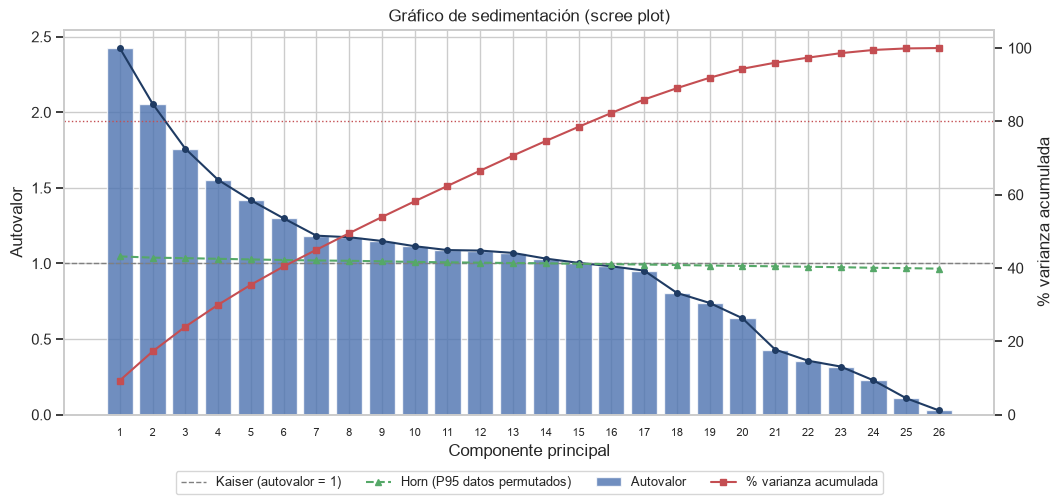

In [22]:
acp.scree_plot(res, cfg.acp["varianza_objetivo"], horn);

**Elección de la cantidad mínima de componentes.**

- **No hay un codo claro.** Los autovalores bajan de 2,4 a 1,2 en las primeras 7 componentes y después forman una
  meseta de componentes con autovalor apenas por encima de 1 hasta la PC15. A partir de la PC18 caen hacia 0
  (la PC26, con 0,03, es lo que queda de la redundancia `USCITY`/`USSTATE` ⊂ EE. UU.).
- **Kaiser y Horn coinciden en 15.** Con n ≈ 730 000, los autovalores de los datos permutados quedan muy cerca de 1
  (P95 entre 0,97 y 1,05), así que Horn converge a Kaiser. La PC15 (1,004) todavía supera a su referencia (0,998) y
  la PC16 (0,981) ya no.
- **El 80 % de varianza pediría 16 componentes y Jolliffe 19**: ninguno de los dos compara contra ruido.
- **Decisión: K = 15** (78,5 % de la varianza). Es la menor cantidad que retiene toda la estructura distinguible del
  ruido. La compresión es modesta (26 → 15) porque las indicadoras de categorías distintas son casi independientes
  entre sí: varias componentes de la meseta representan prácticamente una sola indicadora.
- **Para la detección de atípicos, K define qué parte es "modelo" y qué parte es "residuo":** lo que quede afuera de
  las 15 componentes se mide con Q.

In [23]:
# Decisión: cantidad mínima de componentes = análisis paralelo de Horn
K = int(criterios["Análisis paralelo de Horn"])
print(f"Componentes retenidas: {K} de {len(res.columnas)} -> {res.varianza['pct_acumulado'].iloc[K - 1]:.1f}% de la varianza")
res.scores.iloc[:, :K].to_parquet(cfg.ruta("scores"))

Componentes retenidas: 15 de 26 -> 78.5% de la varianza


### Interpretación de las componentes retenidas

Cargas = autovector × √autovalor: con datos estandarizados son la correlación entre cada variable y la componente.

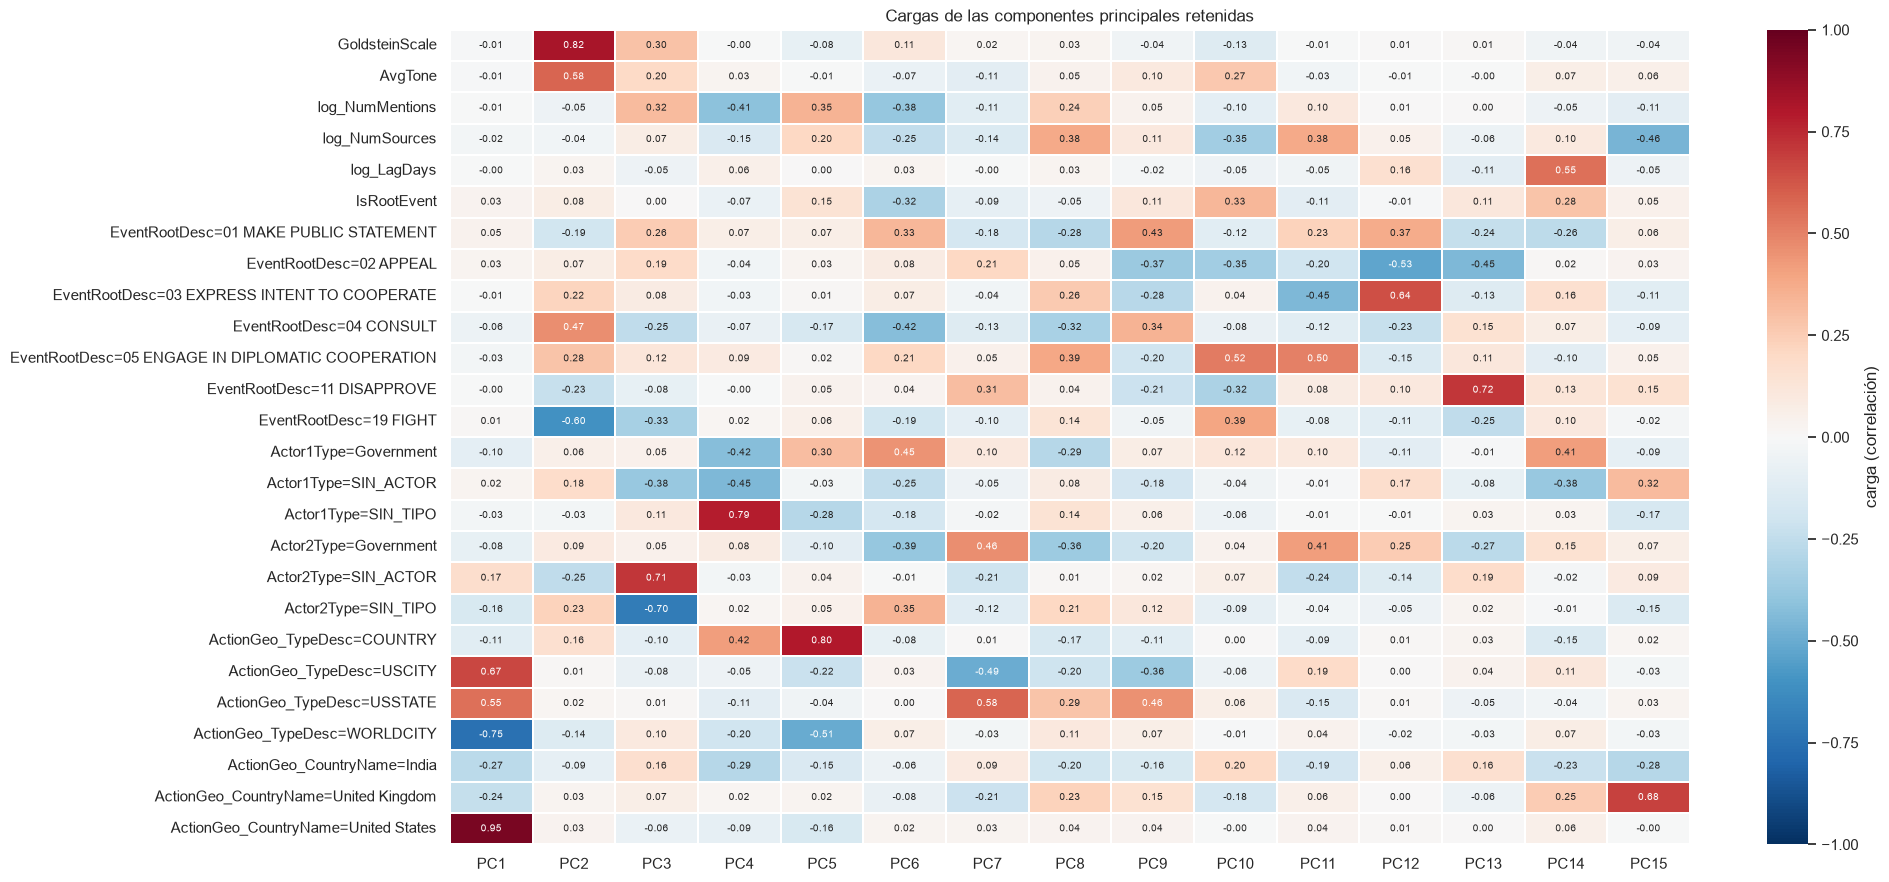

In [24]:
cargas = res.cargas(K)
acp.heatmap_cargas(cargas);

In [25]:
acp.cargas_principales(cargas, k=4)

,#1,#2,#3,#4
componente,,,,
PC1,ActionGeo_CountryName=United States (+0.95),ActionGeo_TypeDesc=WORLDCITY (-0.75),ActionGeo_TypeDesc=USCITY (+0.67),ActionGeo_TypeDesc=USSTATE (+0.55)
PC2,GoldsteinScale (+0.82),EventRootDesc=19 FIGHT (-0.60),AvgTone (+0.58),EventRootDesc=04 CONSULT (+0.47)
PC3,Actor2Type=SIN_ACTOR (+0.71),Actor2Type=SIN_TIPO (-0.70),Actor1Type=SIN_ACTOR (-0.38),EventRootDesc=19 FIGHT (-0.33)
PC4,Actor1Type=SIN_TIPO (+0.79),Actor1Type=SIN_ACTOR (-0.45),Actor1Type=Government (-0.42),ActionGeo_TypeDesc=COUNTRY (+0.42)
PC5,ActionGeo_TypeDesc=COUNTRY (+0.80),ActionGeo_TypeDesc=WORLDCITY (-0.51),log_NumMentions (+0.35),Actor1Type=Government (+0.30)
PC6,Actor1Type=Government (+0.45),EventRootDesc=04 CONSULT (-0.42),Actor2Type=Government (-0.39),log_NumMentions (-0.38)
PC7,ActionGeo_TypeDesc=USSTATE (+0.58),ActionGeo_TypeDesc=USCITY (-0.49),Actor2Type=Government (+0.46),EventRootDesc=11 DISAPPROVE (+0.31)
PC8,EventRootDesc=05 ENGAGE IN DIPLOMATIC COOPERATION (+0.39),log_NumSources (+0.38),Actor2Type=Government (-0.36),EventRootDesc=04 CONSULT (-0.32)
PC9,ActionGeo_TypeDesc=USSTATE (+0.46),EventRootDesc=01 MAKE PUBLIC STATEMENT (+0.43),EventRootDesc=02 APPEAL (-0.37),ActionGeo_TypeDesc=USCITY (-0.36)


**Interpretación de las componentes.**

| Componente | Variables dominantes | Lectura |
|---|---|---|
| PC1 | EE. UU. (+0,95), `USCITY` (+0,67), `USSTATE` (+0,55) vs `WORLDCITY` (−0,75) | **Geografía: EE. UU. vs. resto del mundo**. Con el 30 % de los eventos, EE. UU. es el principal eje de variación |
| PC2 | Goldstein (+0,82), tono (+0,58), CONSULT (+0,47) vs FIGHT (−0,60) | **Cooperación ↔ conflicto**, el eje que en el TP3 era la PC1 |
| PC3 | `Actor2Type=SIN_ACTOR` (+0,71) vs `SIN_TIPO` (−0,70) | **Estructura del actor 2**: evento de un solo actor vs actor identificado solo por país |
| PC4 | `Actor1Type=SIN_TIPO` (+0,79), `COUNTRY` (+0,42) vs `Government`, `SIN_ACTOR` | **Estructura del actor 1**: actores-país con geocodificación a nivel país |
| PC5 | `COUNTRY` (+0,80), `log_NumMentions` (+0,35) vs `WORLDCITY` | **Precisión de la geocodificación** (los eventos fechados a nivel país tienen algo más de menciones) |
| PC6–PC13 | una o dos indicadoras de `EventRootDesc` / `Government` por componente | **Meseta**: cada componente representa casi una categoría |
| PC14 | `log_LagDays` (+0,55) | **Desfase de fecha** |
| PC15 | Reino Unido (+0,68) vs `log_NumSources` (−0,46) | **Cobertura multi-fuente** (contrastada con UK) |

Lo importante para el punto siguiente: **`log_LagDays` y `log_NumSources` recién aparecen en las últimas componentes
retenidas** (PC8, PC14 y PC15), que tienen autovalores ≈ 1. Su variación no se explica con la estructura principal.
Por eso un valor extremo en esas variables infla tanto T² (al dividir por un λ chico) como Q (por lo que queda fuera
del modelo).

## 2.5 Detección de eventos atípicos multivariantes

Sobre el modelo de K componentes cada evento se evalúa con dos estadísticos complementarios (`src/atipicos.py`):

| Estadístico | Fórmula | Qué detecta | Límite (α = 0,001) |
|---|---|---|---|
| **T² de Hotelling** | $T^2_i = \sum_{j=1}^{K} t_{ij}^2/\lambda_j$ | distancia de Mahalanobis *dentro* del subespacio del ACP: combinación extrema de variables que el modelo sí representa | $\chi^2_K(1-\alpha)$ |
| **SPE / Q** | $Q_i = \lVert z_i - \hat z_i \rVert^2 = \sum_{j>K} t_{ij}^2$ | error de reconstrucción *fuera* del modelo: eventos que rompen la estructura de correlación | Jackson–Mudholkar |

Un evento es atípico si supera cualquiera de los dos límites. Para cada atípico se calculan las **contribuciones por
variable** a T² y a Q, lo que permite explicar *por qué* es raro.

In [26]:
alfa = cfg.atipicos["alfa"]
det = atipicos.detectar(res, K, alfa)
print(f"Límite T² = χ²_{K}({1 - alfa}) = {det.attrs['limite_T2']:.1f} | Límite Q (Jackson–Mudholkar) = {det.attrs['limite_Q']:.1f}")
resumen = det["tipo_atipico"].value_counts().to_frame("eventos")
resumen["%"] = (100 * resumen["eventos"] / len(det)).round(2)
print(f"Atípicos: {(det['tipo_atipico'] != 'normal').sum():,} ({100 * (det['tipo_atipico'] != 'normal').mean():.2f}%) "
      f"| esperados bajo normalidad multivariante ≈ 2·α·n = {alfa * len(det) * 2:,.0f}")
resumen

Límite T² = χ²_15(0.999) = 37.7 | Límite Q (Jackson–Mudholkar) = 19.5
Atípicos: 16,702 (2.29%) | esperados bajo normalidad multivariante ≈ 2·α·n = 1,459


,eventos,%
tipo_atipico,,
normal,712961,97.71
solo T2,6259,0.86
T2 y Q,6150,0.84
solo Q,4293,0.59


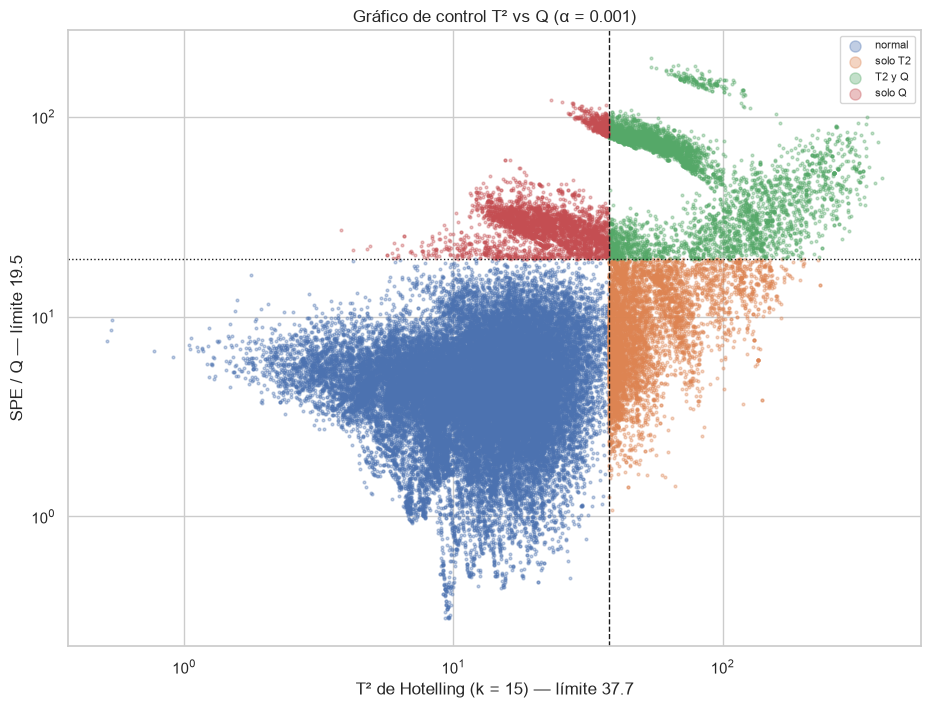

In [27]:
color = pd.Series(det["tipo_atipico"].to_numpy(), index=det.index, name="tipo")
atipicos.grafico_control(det, color=color, semilla=cfg.acp["semilla"]);

In [28]:
# Control: las contribuciones por variable de cada evento suman exactamente su T²
pos = np.flatnonzero((det["tipo_atipico"] != "normal").to_numpy())[:1000]
C = atipicos.contribuciones_t2(res, K, pos)
print("Máx |Σ contribuciones − T²| en 1000 atípicos:", float(np.abs(C.sum(axis=1).to_numpy() - det["T2"].to_numpy()[pos]).max()))

Máx |Σ contribuciones − T²| en 1000 atípicos: 1.7053025658242404e-13


In [29]:
expl = atipicos.explicar(res, K, det)
tabla = atipicos.tabla_atipicos(eventos, det, expl)
tabla["motivo"].value_counts().to_frame("eventos atípicos")

,eventos atípicos
motivo,
Desfase entre evento y publicación,8483
Cobertura inusual (muchas fuentes),5597
Combinación poco frecuente de categorías,2307
Tono extremo,204
Cobertura inusual (muchas menciones),111


In [30]:
# Perfil de los atípicos frente al resto (medianas y proporciones)
ev = eventos.set_index("GlobalEventID").loc[det.index]
es_at = (det["tipo_atipico"] != "normal").to_numpy()
num = ["GoldsteinScale", "AvgTone", "NumMentions", "NumSources", "NumArticles", "LagDays"]
perfil_at = pd.DataFrame({"atípicos (mediana)": ev.loc[es_at, num].median(), "resto (mediana)": ev.loc[~es_at, num].median(),
                          "atípicos (media)": ev.loc[es_at, num].mean(), "resto (media)": ev.loc[~es_at, num].mean()}).round(2)
perfil_at.loc["% con LagDays > 0"] = [100 * (ev.loc[es_at, "LagDays"] > 0).mean(), 100 * (ev.loc[~es_at, "LagDays"] > 0).mean()] * 2
perfil_at.loc["% con NumSources > 1"] = [100 * (ev.loc[es_at, "NumSources"] > 1).mean(), 100 * (ev.loc[~es_at, "NumSources"] > 1).mean()] * 2
perfil_at.round(2)

,atípicos (mediana),resto (mediana),atípicos (media),resto (media)
GoldsteinScale,1.9,1.0,0.49,0.48
AvgTone,-2.1,-1.89,-2.36,-1.96
NumMentions,6.0,4.0,10.93,4.54
NumSources,1.0,1.0,2.42,1.02
NumArticles,6.0,4.0,10.51,4.44
LagDays,30.0,0.0,134.51,0.04
% con LagDays > 0,53.91,0.78,53.91,0.78
% con NumSources > 1,38.01,1.84,38.01,1.84


In [31]:
# ¿Cuánto más frecuente es cada categoría entre los atípicos? (lift = % en atípicos / % en el total)
lifts = []
for c in ["QuadClassDesc", "EventRootDesc", "ActionGeo_CountryName", "Actor1Type"]:
    p_at = ev.loc[es_at, c].value_counts(normalize=True)
    p_tot = ev[c].value_counts(normalize=True)
    l = pd.DataFrame({"variable": c, "% atípicos": 100 * p_at, "% total": 100 * p_tot}).dropna()
    l["lift"] = l["% atípicos"] / l["% total"]
    lifts.append(l[l["% atípicos"] >= 2].sort_values("lift", ascending=False).head(4))
pd.concat(lifts).round(2)

,variable,% atípicos,% total,lift
Conflicto material,QuadClassDesc,15.12,13.24,1.14
Conflicto verbal,QuadClassDesc,14.27,13.87,1.03
Cooperación verbal,QuadClassDesc,61.49,61.73,1.00
Cooperación material,QuadClassDesc,9.12,11.16,0.82
03 EXPRESS INTENT TO COOPERATE,EventRootDesc,12.45,6.06,2.06
11 DISAPPROVE,EventRootDesc,9.15,6.84,1.34
19 FIGHT,EventRootDesc,7.07,5.86,1.21
17 COERCE,EventRootDesc,5.06,4.61,1.10
United Kingdom,ActionGeo_CountryName,16.98,5.27,3.22
Australia,ActionGeo_CountryName,6.45,2.22,2.90


### Eventos para investigar

Muchos atípicos salen del **mismo artículo** (GDELT extrae varios eventos de una nota). Se agrupan por `SOURCEURL`
para ver las historias detrás y se listan los eventos de mayor puntaje (cuántas veces superan el límite más exigido).

In [32]:
por_url = (tabla.groupby("SOURCEURL")
           .agg(eventos=("GlobalEventID", "size"), puntaje_max=("puntaje", "max"), fuentes=("NumSources", "max"),
                tono=("AvgTone", "first"), lag=("LagDays", "max"), motivo=("motivo", lambda s: s.mode().iloc[0]),
                raiz=("EventRootDesc", lambda s: s.mode().iloc[0]), pais=("ActionGeo_CountryName", lambda s: s.mode().iloc[0]))
           .sort_values("puntaje_max", ascending=False))
print(f"{len(tabla):,} eventos atípicos provienen de {len(por_url):,} URLs distintas")
por_url.head(15).round(2)

16,702 eventos atípicos provienen de 6,236 URLs distintas


,eventos,puntaje_max,fuentes,tono,lag,motivo,raiz,pais
SOURCEURL,,,,,,,,
https://www.irishexaminer.com/world/arid-41925500.html,1,10.38,20,-9.94,0,Cobertura inusual (muchas fuentes),01 MAKE PUBLIC STATEMENT,United States
https://www.business-standard.com/companies/news/kaizad-bharucha-to-exit-hdfc-bank-at-end-of-december-after-three-decades-126101700674_1.html,2,10.05,1,1.89,3650,Desfase entre evento y publicación,04 CONSULT,India
https://www.newarkadvertiser.co.uk/national/government-being-cautious-about-public-announcements-on-jackdaw-and-rosebank-173071/,4,10.05,20,-1.40,0,Cobertura inusual (muchas fuentes),03 EXPRESS INTENT TO COOPERATE,United Kingdom
https://www.wandsworthguardian.co.uk/news/national/26637686.university-staff-strike-dispute-job-cuts-compulsory-redundancies/,1,9.73,19,-7.53,0,Cobertura inusual (muchas fuentes),13 THREATEN,SIN_UBICACION
https://aninews.in/news/national/general-news/ayush-innovation-sees-eightfold-rise-in-patent-filings20261016180611/,1,9.37,1,8.08,3650,Desfase entre evento y publicación,05 ENGAGE IN DIPLOMATIC COOPERATION,India
https://www.hexham-courant.co.uk/news/national/26638394.school-roof-collapse-kills-least-28-children-teacher-pakistan/,2,9.30,19,-5.85,0,Cobertura inusual (muchas fuentes),07 PROVIDE AID,Pakistan
https://www.aol.co.uk/articles/andy-burnham-sent-huge-warning-134000000.html,1,9.19,1,-2.77,3650,Desfase entre evento y publicación,05 ENGAGE IN DIPLOMATIC COOPERATION,United Kingdom
https://www.zerohedge.com/ai/bill-gates-fearmongers-grim-ai-cyberattack-surprises,27,9.08,1,-3.31,3650,Desfase entre evento y publicación,04 CONSULT,United Kingdom
https://www.cambstimes.co.uk/news/national/26634303.pope-leo-spent-tranquil-night-hospital-cancer-surgery-vatican-says/,5,9.07,17,-1.62,0,Cobertura inusual (muchas fuentes),04 CONSULT,United States


In [33]:
cols_ver = ["GlobalEventID", "DateAdded", "EventRootDesc", "Actor1Name", "Actor2Name", "ActionGeo_CountryName",
            "GoldsteinScale", "AvgTone", "NumMentions", "NumSources", "LagDays", "tipo_atipico", "puntaje", "motivo", "variables_T2"]
tabla.head(cfg.atipicos["top_investigar"])[cols_ver].round({"AvgTone": 2, "puntaje": 2})

,GlobalEventID,DateAdded,EventRootDesc,Actor1Name,Actor2Name,ActionGeo_CountryName,GoldsteinScale,AvgTone,NumMentions,NumSources,LagDays,tipo_atipico,puntaje,motivo,variables_T2
0,1328541516,2026-10-18 09:30:00,01 MAKE PUBLIC STATEMENT,ISRAEL,JOURNALIST,United States,3.4,-9.94,162,20,0,T2 y Q,10.38,Cobertura inusual (muchas fuentes),"log_NumSources (83%), log_NumMentions (12%), ActionGeo_TypeDesc=USCITY (1%)"
1,1328448504,2026-10-17 12:45:00,04 CONSULT,NaN,BANK,India,7.0,1.89,10,1,3650,T2 y Q,10.05,Desfase entre evento y publicación,"log_LagDays (93%), IsRootEvent (4%), EventRootDesc=04 CONSULT (4%)"
2,1328254641,2026-10-16 09:00:00,03 EXPRESS INTENT TO COOPERATE,ENERGY SECRETARY,LONDON,United Kingdom,4.0,-1.40,154,20,0,T2 y Q,10.05,Cobertura inusual (muchas fuentes),"log_NumSources (81%), log_NumMentions (13%), EventRootDesc=03 EXPRESS INTENT..."
3,1327938381,2026-10-14 16:45:00,13 THREATEN,GLASGOW,UNIVERSITY,SIN_UBICACION,-7.0,-7.53,190,19,0,T2 y Q,9.73,Cobertura inusual (muchas fuentes),"log_NumSources (84%), log_NumMentions (14%), AvgTone (1%)"
4,1328254273,2026-10-16 09:00:00,03 EXPRESS INTENT TO COOPERATE,INVESTOR,NaN,United Kingdom,5.2,-1.39,100,20,0,T2 y Q,9.52,Cobertura inusual (muchas fuentes),"log_NumSources (83%), log_NumMentions (12%), EventRootDesc=03 EXPRESS INTENT..."
5,1328293242,2026-10-16 13:15:00,05 ENGAGE IN DIPLOMATIC COOPERATION,INTELLECTUAL,NaN,India,8.0,8.08,2,1,3650,T2 y Q,9.37,Desfase entre evento y publicación,"log_LagDays (83%), AvgTone (5%), EventRootDesc=05 ENGAGE IN DIPLOMATIC COOPE..."
6,1328068235,2026-10-15 09:45:00,07 PROVIDE AID,PESHAWAR,NaN,Pakistan,7.4,-5.85,114,19,0,T2 y Q,9.30,Cobertura inusual (muchas fuentes),"log_NumSources (86%), log_NumMentions (13%), Actor1Type=SIN_TIPO (1%)"
7,1328448505,2026-10-17 12:45:00,04 CONSULT,BANK,NaN,India,7.0,1.89,10,1,3650,T2 y Q,9.22,Desfase entre evento y publicación,"log_LagDays (88%), IsRootEvent (4%), EventRootDesc=04 CONSULT (3%)"
8,1328710598,2026-10-19 14:15:00,05 ENGAGE IN DIPLOMATIC COOPERATION,NaN,UNITED KINGDOM,United Kingdom,3.5,-2.77,10,1,3650,T2 y Q,9.19,Desfase entre evento y publicación,"log_LagDays (72%), ActionGeo_CountryName=United Kingdom (25%), EventRootDesc..."
9,1328254579,2026-10-16 09:00:00,03 EXPRESS INTENT TO COOPERATE,UNITED KINGDOM,UNITED KINGDOM,United Kingdom,4.0,-1.39,40,20,0,T2 y Q,9.10,Cobertura inusual (muchas fuentes),"log_NumSources (86%), log_NumMentions (8%), EventRootDesc=03 EXPRESS INTENT ..."


In [34]:
# Sindicación: dominios de las notas con muchas fuentes entre los atípicos
sind = tabla[tabla["motivo"].str.startswith("Cobertura")]
print(f"Atípicos por cobertura: {len(sind):,} | dominios distintos: {sind['SourceDomain'].nunique()}")
display(sind["SourceDomain"].value_counts().head(10).to_frame("eventos"))
# Ejemplo: una misma nota publicada por muchas fuentes con exactamente el mismo tono
ej = por_url[por_url["motivo"].str.startswith("Cobertura")].index[0]
eventos.loc[eventos["SOURCEURL"].eq(ej), ["GlobalEventID", "EventDesc", "Actor1Name", "Actor2Name", "AvgTone", "NumMentions", "NumSources", "NumArticles"]]

Atípicos por cobertura: 5,708 | dominios distintos: 635


,eventos
SourceDomain,
bordermail.com.au,95
eveshamjournal.co.uk,72
brisbanetimes.com.au,63
winnipegfreepress.com,60
theleader.com.au,57
yourlocalguardian.co.uk,54
clickondetroit.com,54
westernadvocate.com.au,52
bournemouthecho.co.uk,48


,GlobalEventID,EventDesc,Actor1Name,Actor2Name,AvgTone,NumMentions,NumSources,NumArticles
576803,1328541516,Make empathetic comment,ISRAEL,JOURNALIST,-9.938032,162,20,162


In [35]:
# Desfase de fecha: GDELT fecha el evento con expresiones relativas del texto ("hace un año", "hace una década")
lag = tabla[tabla["motivo"].str.startswith("Desfase")]
print(f"Atípicos por desfase: {len(lag):,}")
display(lag["LagDays"].value_counts().to_frame("eventos"))
lag[lag["LagDays"].eq(lag["LagDays"].max())][["GlobalEventID", "EventDate", "DateAdded", "EventDesc", "Actor1Name", "Actor2Name", "SOURCEURL"]].head(8)

Atípicos por desfase: 8,483


,eventos
LagDays,
365,4135
30,3980
7,196
3650,166
0,6


,GlobalEventID,EventDate,DateAdded,EventDesc,Actor1Name,Actor2Name,SOURCEURL
1,1328448504,2016-10-19,2026-10-17 12:45:00,Engage in negotiation,NaN,BANK,https://www.business-standard.com/companies/news/kaizad-bharucha-to-exit-hdf...
5,1328293242,2016-10-18,2026-10-16 13:15:00,Sign formal agreement,INTELLECTUAL,NaN,https://aninews.in/news/national/general-news/ayush-innovation-sees-eightfol...
7,1328448505,2016-10-19,2026-10-17 12:45:00,Engage in negotiation,BANK,NaN,https://www.business-standard.com/companies/news/kaizad-bharucha-to-exit-hdf...
8,1328710598,2016-10-21,2026-10-19 14:15:00,Defend verbally,NaN,UNITED KINGDOM,https://www.aol.co.uk/articles/andy-burnham-sent-huge-warning-134000000.html
10,1327917965,2016-10-16,2026-10-14 14:45:00,Host a visit,NaN,UNITED KINGDOM,https://www.zerohedge.com/ai/bill-gates-fearmongers-grim-ai-cyberattack-surp...
14,1327917967,2016-10-16,2026-10-14 14:45:00,"Threaten, not specified below",NaN,UNITED KINGDOM,https://www.zerohedge.com/ai/bill-gates-fearmongers-grim-ai-cyberattack-surp...
18,1328274847,2016-10-18,2026-10-16 11:30:00,Provide economic aid,GOVERNMENT,NaN,https://www.moneycontrol.com/news/india/the-next-big-bets-where-startup-capi...
24,1328047960,2016-10-17,2026-10-15 07:30:00,"Disapprove, not specified below",PANAMA,UNITED STATES,https://www.livemint.com/news/panama-indian-business-investment-latin-americ...


In [36]:
# Combinaciones poco frecuentes / tono extremo (lo que queda al sacar desfase y cobertura)
resto = tabla[~tabla["motivo"].str.startswith(("Desfase", "Cobertura"))]
print(f"Atípicos por otras combinaciones: {len(resto):,}")
display(resto["motivo"].value_counts().to_frame("eventos"))
resto.head(10)[cols_ver].round({"AvgTone": 2, "puntaje": 2})

Atípicos por otras combinaciones: 2,511


,eventos
motivo,
Combinación poco frecuente de categorías,2307
Tono extremo,204


,GlobalEventID,DateAdded,EventRootDesc,Actor1Name,Actor2Name,ActionGeo_CountryName,GoldsteinScale,AvgTone,NumMentions,NumSources,LagDays,tipo_atipico,puntaje,motivo,variables_T2
5449,1328595331,2026-10-18 19:45:00,17 COERCE,HERAT,CRIMINAL,SIN_UBICACION,-5.0,-38.89,10,1,0,solo Q,3.11,Tono extremo,"AvgTone (87%), GoldsteinScale (9%), log_NumMentions (3%)"
6394,1328754527,2026-10-19 18:45:00,18 ASSAULT,JEWISH,NaN,United Kingdom,-9.0,-32.50,10,1,0,solo Q,2.35,Tono extremo,"ActionGeo_CountryName=United Kingdom (44%), AvgTone (28%), GoldsteinScale (10%)"
7212,1328631672,2026-10-19 04:00:00,14 PROTEST,TIRANA,ALBANIA,Albania,-7.5,-30.43,10,1,0,solo Q,1.85,Tono extremo,"AvgTone (72%), GoldsteinScale (15%), ActionGeo_TypeDesc=WORLDCITY (4%)"
7449,1328581725,2026-10-18 17:00:00,01 MAKE PUBLIC STATEMENT,NaN,JUDGE,United Kingdom,-2.0,-27.27,1,1,0,solo Q,1.79,Tono extremo,"ActionGeo_CountryName=United Kingdom (39%), Actor1Type=SIN_ACTOR (20%), AvgT..."
7450,1328594230,2026-10-18 19:30:00,13 THREATEN,FRANCE,RIOTER,France,-5.8,-29.63,10,1,0,solo Q,1.79,Tono extremo,"AvgTone (41%), Actor1Type=Government (20%), ActionGeo_TypeDesc=COUNTRY (14%)"
7471,1328631674,2026-10-19 04:00:00,17 COERCE,ALBANIA,TIRANA,Albania,-9.0,-30.43,10,1,0,solo Q,1.78,Tono extremo,"AvgTone (67%), GoldsteinScale (17%), Actor2Type=SIN_TIPO (6%)"
7650,1328582083,2026-10-18 17:00:00,01 MAKE PUBLIC STATEMENT,JUDGE,UNITED KINGDOM,United Kingdom,-2.0,-27.27,2,1,0,solo Q,1.75,Tono extremo,"ActionGeo_CountryName=United Kingdom (44%), AvgTone (22%), EventRootDesc=01 ..."
7961,1328397554,2026-10-17 02:30:00,07 PROVIDE AID,EGYPT,NaN,Egypt,7.0,28.57,4,1,0,solo Q,1.68,Tono extremo,"AvgTone (55%), ActionGeo_TypeDesc=COUNTRY (12%), Actor2Type=SIN_ACTOR (9%)"
8280,1327910357,2026-10-14 14:00:00,13 THREATEN,NaN,UGANDA,Uganda,-4.4,-27.91,20,1,0,solo Q,1.63,Tono extremo,"AvgTone (32%), Actor1Type=SIN_ACTOR (26%), ActionGeo_TypeDesc=COUNTRY (12%)"
8377,1328317764,2026-10-16 15:45:00,03 EXPRESS INTENT TO COOPERATE,NaN,UNITED KINGDOM,United Kingdom,4.0,-0.30,4,1,30,solo T2,1.62,Combinación poco frecuente de categorías,"EventRootDesc=03 EXPRESS INTENT TO COOPERATE (28%), ActionGeo_CountryName=Un..."


**Interpretación de los atípicos.**

- **Magnitud.** 16 702 eventos (2,29 %) superan algún límite, contra ≈ 1 460 esperados si los datos fueran normales
  multivariantes. El exceso (×11) no es un error: la matriz tiene 20 indicadoras binarias y conteos discretos con colas
  pesadas, así que los límites χ² y de Jackson–Mudholkar funcionan como **umbral de referencia**, no como una
  probabilidad exacta. Por eso la tabla se ordena por `puntaje` (cuántas veces se supera el límite) y la
  priorización se hace sobre ese orden.
- **Gráfico de control.** Las franjas de puntos son grupos de eventos con el mismo perfil discreto. Las bandas
  superiores corresponden a los desfases (Q mediano ≈ 27 con 30 días, ≈ 78 con 365 días y ≈ 150 con 3650 días). La
  "cola" con T² alto y Q moderado (T² mediano 67, Q 14) son los eventos con muchas fuentes.
- **Los atípicos no son eventos más conflictivos.** Goldstein medio 0,49 contra 0,48 del resto: la rareza no está en
  *qué pasa* sino en **cómo se registra y cuánto se difunde**. El 53,9 % tiene desfase de fecha (0,8 % en el resto) y
  el 38 % tiene más de una fuente (1,8 % en el resto).

**Tres familias de eventos para investigar:**

1. **Desfase entre evento y publicación (8 483 eventos, 51 %).** Casi todos con desfase de 365 o 30 días, y 166 de
   3650. Al revisar las notas, son noticias actuales que GDELT fechó con una expresión relativa del texto. Por ejemplo,
   *"Kaizad Bharucha to exit HDFC Bank… after three decades"* (business-standard) quedó fechado el 19/10/2016, y una
   nota de zerohedge sobre IA generó 27 eventos atípicos, todos con 3650 días de desfase. **Para el negocio periodístico son un problema
   de calidad de datos**: cualquier serie temporal construida con `Day` los ubicaría en otro año. Conviene marcarlos o
   usar `DATEADDED` como fecha de referencia.
2. **Cobertura inusual (5 708 eventos, 34 %).** Notas replicadas por hasta 20 fuentes, todas con **exactamente el
   mismo tono**, porque es el mismo texto. Es la huella de la **sindicación**: una nota de agencia reproducida por redes
   de diarios locales. El Reino Unido aparece 3,2 veces más entre los atípicos que en el total y Australia 2,9 veces
   (dominios como `huntspost.co.uk`, `halsteadgazette.co.uk`, `bordermail.com.au`, `theleader.com.au`). Son **las
   historias más difundidas de la semana** y las que más vale la pena mirar desde el punto de vista editorial. Por
   ejemplo: el ataque de colonos israelíes a un periodista y las reacciones diplomáticas (19–20 fuentes, tono ≈ −10),
   el debate por los yacimientos Jackdaw y Rosebank en el Reino Unido (20 fuentes, 154 menciones), la internación del
   papa León (17 fuentes) y los ataques con drones a buques en el mar Negro (16 eventos de una misma nota).
3. **Combinaciones poco frecuentes y tono extremo (2 511 eventos, 15 %).** Eventos con tono cercano a los extremos
   de la escala (−38,9 en una coerción en Herat, −32,5 en una agresión en el Reino Unido, −30,4 en protestas en
   Tirana, +28,6 en ayuda de Egipto) o con combinaciones raras de tipo de actor, acción y país. Los de tono extremo
   son casi todos `solo Q` (198 de 204): rompen la correlación habitual entre tono, Goldstein y tipo de acción. Las
   combinaciones raras son en su mayoría `solo T2` (2 139): combinaciones extremas de ejes que el modelo sí representa.

### Exportación

La tabla de atípicos se exporta **aparte** de la OBT, en parquet (para análisis) y CSV (para abrir en una planilla).
Columnas: atributos del evento (de la OBT limpia), `T2`, `Q`, `T2_rel`/`Q_rel` (estadístico / límite),
`tipo_atipico`, `puntaje`, las tres variables que más contribuyen a T² y a Q, y el `motivo`.

In [37]:
tabla.to_parquet(cfg.ruta("atipicos"), index=False)
tabla.to_csv(cfg.ruta("atipicos_csv"), index=False)
print(f"{len(tabla):,} eventos atípicos exportados -> {cfg.rutas['atipicos']} y {cfg.rutas['atipicos_csv']}")
pd.read_parquet(cfg.ruta("atipicos")).dtypes.to_frame("tipo").T

16,702 eventos atípicos exportados -> data/processed/eventos_atipicos.parquet y data/processed/eventos_atipicos.csv


,GlobalEventID,DateAdded,EventDate,LagDays,EventCode,EventDesc,EventRootDesc,QuadClassDesc,Actor1Code,Actor1Name,Actor1Type,Actor2Code,Actor2Name,Actor2Type,ActionGeo_FullName,ActionGeo_CountryName,GoldsteinScale,AvgTone,NumMentions,NumSources,NumArticles,SourceDomain,SOURCEURL,T2,Q,T2_rel,Q_rel,tipo_atipico,puntaje,variables_T2,variables_Q,motivo
tipo,Int64,datetime64[us],datetime64[us],Int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,float64,Int64,Int64,Int64,str,str,float64,float64,float64,float64,str,float64,str,str,str


# 3) Conclusiones

1. **Ingesta.** Los 672 archivos de 15 minutos de la ventana del 13 al 19/10/2026 se obtuvieron del manifiesto de
   GDELT con verificación MD5, sin faltantes, y se integraron en una OBT de 729 663 eventos × 81 columnas
   (61 originales + 20 descriptivas/derivadas) guardada en parquet.
2. **Limpieza.** Casi todos los faltantes son **estructurales** (actor ausente, actor sin tipo, sin geocodificación) y se
   recodificaron como categorías explícitas en lugar de descartarse. El único nulo real (Goldstein en 3 eventos con
   un código CAMEO fuera del codebook) se imputó con la regla del propio codebook. Se descartaron 12 columnas
   casi vacías (> 90 % nulos) y `NumArticles` por redundancia. No se perdió ningún evento.
3. **Matriz.** Con el umbral del 5 % las 5 categóricas pasan de ~340 a 25 categorías, y `OTHER` es una de las más
   grandes en casi todas. `QuadClass` se excluyó porque es combinación lineal exacta de las indicadoras de la raíz CAMEO
   (verificado). Matriz final: 729 663 × 26.
4. **ACP.** La **cantidad mínima de componentes es 15** (Horn = Kaiser, 78,5 % de la varianza). La estructura principal
   es geográfica (EE. UU. vs. resto) y de cooperación/conflicto. La compresión es modesta porque las indicadoras son
   casi independientes.
5. **Atípicos.** Con T² de Hotelling y SPE al 0,1 % se identificaron **16 702 eventos atípicos** (2,3 %), exportados a
   `data/processed/eventos_atipicos.parquet` / `.csv` con el estadístico, las variables que lo explican y un motivo.
   Lo "raro" del ecosistema GDELT no son los eventos más violentos, sino:
   - **artefactos de fechado** (eventos actuales con `Day` desplazado 1 mes, 1 año o 10 años), que hay que corregir
     antes de cualquier análisis temporal;
   - **historias sindicadas** en redes de diarios locales del Reino Unido y Australia: las de mayor difusión de la
     semana;
   - **eventos con tono extremo o combinaciones inusuales**, casos aislados para revisión manual.

# 4) Guía de instrucciones para la IA (human-in-the-loop)

_Mismo contenido que [`GUIA_IA.md`](../GUIA_IA.md)._


**Herramienta:** Claude Opus 5.5 en Claude Code (agente con acceso al repositorio y a la terminal).
**Propósito:** generar el código fuente (`src/`), armar el notebook y redactar las interpretaciones a partir de los
resultados. Las decisiones metodológicas se tomaron en cada punto de control (🔎) antes de seguir.

La guía tiene una instrucción por etapa. Cada instrucción dice **qué hay que pedir**, **qué hay que verificar** antes
de aceptar el resultado y **qué se decidió**. Para reproducir el trabajo, hay que darlas en orden en una sesión
abierta en la raíz del repositorio.

---

## 0. Contexto y estructura

> Leé la carpeta `TP3/` (README, `config.toml`, `src/`, notebook) y replicá la misma arquitectura en `TP4/`:
> `config.toml` con todos los parámetros, `src/` con un módulo por etapa del flujo de datos, `data/raw` para los
> crudos inmutables, `data/processed` para las salidas derivadas (ninguna de las dos se versiona) y `notebooks/TP4.ipynb`.
> Usá el entorno virtual `.env` del repo. El notebook tiene que poder regenerar todo desde cero.

🔎 Verificar que `.gitignore` excluya `data/` salvo los `.gitkeep` y que los nombres de módulos sigan la convención del TP3.

## 1. Ingesta y One Big Table

> Armá el manifiesto de la ventana a partir de `masterfilelist.txt`, sin bajar el archivo completo (~130 MB):
> pedí solo la cola con un HTTP Range y agrandala hasta cubrir el inicio de la ventana. Fijá la ventana en
> `config.toml` (7 días completos en UTC, del 13 al 19/10/2026) para que sea reproducible. Descargá los `export.CSV.zip`
> en paralelo con reintentos y backoff, **validando el MD5 del manifiesto**, y parseá las 61 columnas del codebook con
> pyarrow, con tipos explícitos: los códigos CAMEO como texto y sin comillas como delimitador.
> Deduplicá por `GlobalEventID` quedándote con el `DATEADDED` más reciente.

🔎 Verificar: 672 archivos esperados (7 × 96), 0 faltantes, 0 MD5 inválidos, `GlobalEventID` único.

> Construí una **tabla desnormalizada** (OBT) con las 61 columnas originales y, al lado, las descripciones de todos los
> códigos (CAMEO evento/base/raíz, QuadClass y sus ejes, tipos y países de los actores, países FIPS de las tres
> geografías, tipo de geocodificación) y atributos derivados: fecha del evento, fecha de publicación, desfase en días,
> hora, día de la semana y dominio del medio. **Conservá los nulos como vienen**: se tratan en la limpieza.
> Guardala en parquet.

🔎 Revisar el diccionario de columnas derivadas y una muestra de filas. Decisión: la OBT reemplaza al esquema estrella
del TP3 porque el análisis no necesita JOINs.

## 2. Diagnóstico de nulos y ceros

> Perfilá cada columna del export: % de nulos y, en las numéricas, % de ceros. Antes de decidir nada, separá
> **nulos estructurales** (la ausencia significa algo), **nulos reales** (el dato debería existir), **ceros
> estructurales** (un 0 que codifica "sin dato") y **ceros válidos** (un 0 que es un valor de la escala), según el
> codebook. Mostrame la evidencia de cada caso (qué códigos tienen Goldstein nulo, qué acciones tienen Goldstein 0,
> dónde está la latitud 0, qué valores toma el desfase).

🔎 Puntos de control y decisiones del equipo:
- Actor ausente o sin tipo → categoría explícita `SIN_ACTOR` / `SIN_TIPO`, **no** descartar filas (se perdería el 30 %
  de los eventos y se sesgaría la muestra hacia eventos con dos actores).
- `ActionGeo_Type = 0` → cero estructural → `SIN_UBICACION`.
- Goldstein nulo (3 eventos, código `1213` fuera del codebook) → imputar con la tabla `CAMEO.goldsteinscale.txt` por
  jerarquía código → base → raíz. Pedir que se agregue esa tabla a las *lookups*.
- Columnas con > 90 % de nulos → fuera del análisis (pero siguen en la OBT). Se eligió 90 % y no 60 % porque con 60 % se
  perdía `Actor2Type1Code`, cuyos nulos son estructurales.

> Agregá un chequeo de *near zero variance* (coeficiente de variación y razón entre la moda y el segundo valor) y la
> correlación entre los conteos en escala log.

🔎 Decisión: `NumSources` y `LagDays` serían NZV por razón de frecuencias, pero **se conservan** porque su rareza es la
señal que se busca. `NumArticles` sale por redundancia (r = 0,99 con `NumMentions`).

## 3. Matriz de datos

> Reutilizá del TP3 la reducción de cardinalidad (`OTHER` para frecuencias < 5 %) y la codificación en indicadoras con
> una categoría de referencia por variable. Categóricas: raíz CAMEO, tipo de actor 1 y 2, tipo de geocodificación y país
> de la acción. Continuas: Goldstein, tono y `log1p` de menciones, fuentes y desfase. Más `IsRootEvent`.

🔎 En el primer ACP apareció un autovalor exactamente 0. Pedir: *"identificá qué combinación lineal genera el
autovalor nulo mirando el último autovector"*. Resultado: las indicadoras de `QuadClass` son combinación lineal exacta
de las de la raíz CAMEO (todas las raíces 01–05 superan el 5 % y la referencia de `QuadClass` es Cooperación verbal).
Decisión: sacar `QuadClass` de la matriz, dejarla solo para interpretar y agregar al notebook una celda que **demuestre**
la dependencia.

## 4. ACP

> Escalá con `StandardScaler` y ajustá el ACP completo. Para la cantidad mínima de componentes compará Kaiser, varianza
> acumulada ≥ 80 %, Jolliffe y **análisis paralelo de Horn** (permutando cada columna por separado sobre una muestra
> de 50 000 filas, 20 repeticiones, P95), y mostralos en el gráfico de sedimentación.

🔎 Verificar media ≈ 0 y desvío = 1 de la matriz escalada, y que la varianza total sea igual a p. Decisión: **K = 15**
(Horn = Kaiser), ya que no hay codo claro y Horn es el único criterio que compara contra ruido.

> Calculá las cargas (autovector × √autovalor), el mapa de calor y las 4 variables de mayor |carga| por componente.

🔎 Revisar que la lectura de cada componente esté respaldada por las cargas (PC1 geografía, PC2 cooperación/conflicto…).

## 5. Atípicos multivariantes

> Sobre el modelo de K componentes calculá el **T² de Hotelling** (límite χ²_K) y el **SPE/Q** (límite de
> Jackson–Mudholkar) con α = 0,001. Marcá como atípico lo que supere cualquiera de los dos y clasificalo como
> `solo T2`, `solo Q` o `T2 y Q`. Para cada atípico calculá las **contribuciones por variable** a T² y a Q, y asignale un
> motivo según la variable que más contribuye. Hacé el gráfico de control T² vs Q.

🔎 Verificar que las contribuciones a T² de cada fila sumen su T². Discutir por qué hay 11 veces más atípicos de los
esperados bajo normalidad (indicadoras binarias y colas pesadas). Decisión: mantener α = 0,001 y **priorizar por puntaje**.

> Perfilá los atípicos frente al resto (medianas, *lift* por categoría), agrupalos por `SOURCEURL` y mostrá ejemplos
> de cada motivo. Exportá la tabla de atípicos aparte, en parquet y CSV.

🔎 Abrir las URLs de los casos de mayor puntaje para confirmar la lectura (sindicación con el mismo tono en todas las
fuentes; desfases de 3650 días en noticias actuales).

## 6. Redacción

> Con los resultados ya ejecutados, redactá las interpretaciones de cada sección y las conclusiones citando solo
> números que aparezcan en las salidas del notebook. Después ejecutalo de punta a punta y verificá que no haya errores
> ni advertencias.

🔎 Revisión final del equipo: contrastar cada cifra del texto con su celda de salida.